# 05 · Regularisation and panel models: two alternatives to hand-picked drivers

Notebook 03 chose drivers by exhaustive search under rules. Two standard alternatives are tested here.

**A. Regularised regression.** Give the model *every* driver at *every* lag (49 macro features) and let a penalty choose:
- **Ridge** (L2): shrinks all coefficients towards zero; handles collinear lags but keeps everything
- **Lasso** (L1): sets many coefficients exactly to zero, so it selects features
- **Elastic Net:** a mix of the two, more stable than Lasso when features are correlated
- **Sign-constrained Lasso:** a Lasso that may only use each driver in its economic direction

The penalty is tuned with **time-series cross-validation** (each fold trains on the past and tests on the future; a shuffled K-fold would leak the future into training).

**B. Panel regression.** Stack the portfolios and estimate common macro sensitivities with portfolio fixed effects. More data per coefficient, but only valid if the portfolios really share slopes, which is tested formally.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn.linear_model import ElasticNetCV, Lasso, LassoCV, LinearRegression, RidgeCV, lasso_path
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from ukstress.config import MODELS_DIR, PORTFOLIOS
from ukstress.features.build import DRIVERS, JUMP_OFF, LAG_GRID, all_lags, covid_dummy, inv_logit_pct, scenario_macro
from ukstress.ingest.build_panel import build_macro, build_panel
from ukstress.models.satellite import design, load_models, project, target
from ukstress.viz import BLUE, GREY, ORANGE, PORTFOLIO_COLOURS, fig_title, save, set_style, subtitle

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.width", 180, "display.precision", 3)

panel, macro = build_panel(), build_macro()
champions = load_models(MODELS_DIR / "champions.json")
LABEL = {p: s["label"] for p, s in PORTFOLIOS.items()}
path = scenario_macro(macro)

## A. Regularised regression on the card portfolio
Features: 7 drivers × 7 lags = 49 macro columns, plus the COVID dummy and the loss rate four quarters earlier (as in the champion). All are standardised so one penalty applies fairly to all.

In [2]:
P = "credit_card"
y_all = target(panel, P)
F = all_lags(macro).join(covid_dummy(macro.index)).assign(y_L4=y_all.shift(4))
data = F.join(y_all.rename("y")).loc["1995Q2":].dropna()
X, y = data.drop(columns="y"), data["y"]
macro_cols = [c for c in X.columns if c not in ("covid", "y_L4")]
print(f"{X.shape[1]} features, {len(y)} quarters ({y.index[0]}–{y.index[-1]}): more features than a third of the observations")

51 features, 125 quarters (1995Q2–2026Q2): more features than a third of the observations


### Lasso path: which features enter first as the penalty relaxes?

Order of entry: ['y_L4', 'unemployment_chg_yoy_L3', 'unemployment_chg_yoy_L2', 'bank_rate_chg_yoy_L3', 'unemployment_L8', 'house_price_growth_yoy_L8', 'bank_rate_chg_yoy_L4', 'cpi_inflation_L8']


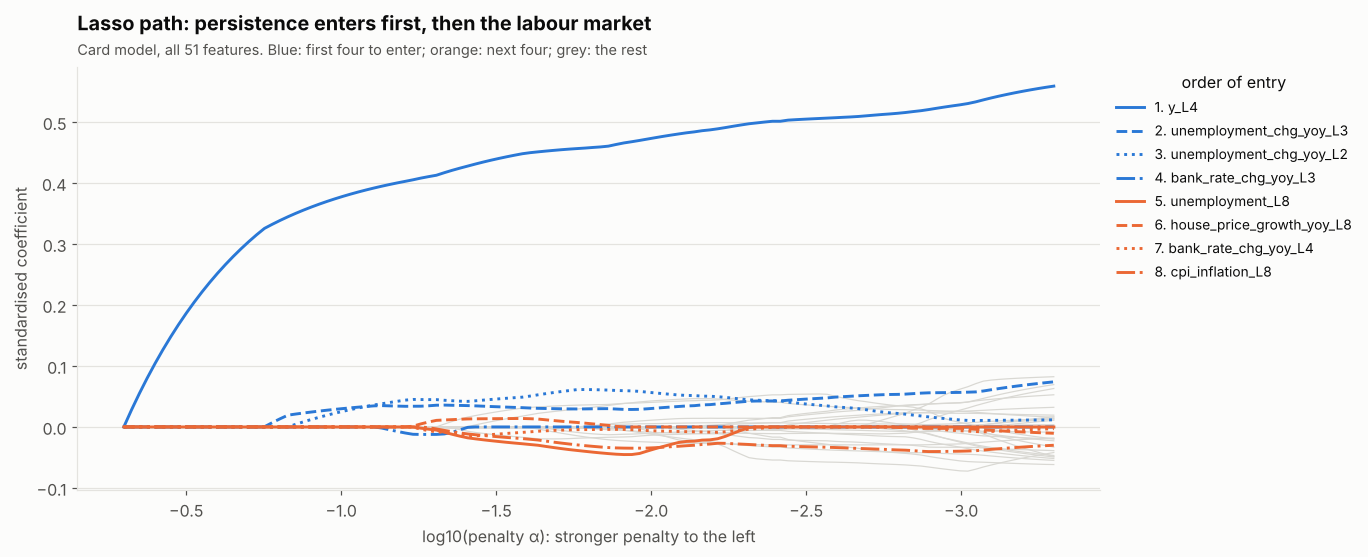

In [3]:
Xs = StandardScaler().fit_transform(X)
alphas, coefs, _ = lasso_path(Xs, y.values - y.mean(), n_alphas=120)
first_entry = {X.columns[j]: alphas[np.argmax(coefs[j] != 0)] if (coefs[j] != 0).any() else 0 for j in range(X.shape[1])}
order = sorted(first_entry, key=first_entry.get, reverse=True)[:8]
fig, ax = plt.subplots(figsize=(12, 5))
styles = ["-", "--", ":", "-."]
for j, c in enumerate(X.columns):
    if c not in order:
        ax.plot(np.log10(alphas), coefs[j], color="#d9d8d3", lw=0.8)
for i, c in enumerate(order):
    j = list(X.columns).index(c)
    ax.plot(np.log10(alphas), coefs[j], color=BLUE if i < 4 else ORANGE, lw=1.9, ls=styles[i % 4],
            label=f"{i + 1}. {c}")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0, title="order of entry", fontsize=9)
ax.invert_xaxis()
ax.set_xlabel("log10(penalty α): stronger penalty to the left")
ax.set_ylabel("standardised coefficient")
ax.set_title("Lasso path: persistence enters first, then the labour market")
subtitle(ax, "Card model, all 51 features. Blue: first four to enter; orange: next four; grey: the rest")
save(fig, "05_lasso_path")
print("Order of entry:", order)
fig

### Time-series cross-validation
Five expanding-window folds. Each model is scored on quarters it has never seen, using one-step-ahead predictions (the actual loss rate four quarters earlier is known at forecast time). The champion OLS model is refitted inside each fold for a fair comparison.

In [4]:
tscv = TimeSeriesSplit(n_splits=5, test_size=16)
champ_cols = [c for c in design(champions[P].spec, y_all, macro).columns if c != "const"]

def positive_lasso(alpha):
    """Lasso that can only use each driver in its economic direction: flip negative-sign drivers, force β ≥ 0."""
    return Lasso(alpha=alpha, positive=True, max_iter=50_000)

sign_vec = pd.Series({c: DRIVERS[c.rsplit("_L", 1)[0]]["sign"] for c in macro_cols} | {"covid": 1, "y_L4": 1})
X_signed = X.copy()
X_signed[macro_cols] = X[macro_cols] * sign_vec[macro_cols]
X_signed["covid"] = -X["covid"]  # COVID lowered losses: flip so a positive coefficient is allowed

models = {
    "Champion OLS (3 drivers)": ("champ", lambda: LinearRegression()),
    "OLS, all 51 features": ("all", lambda: make_pipeline(StandardScaler(), LinearRegression())),
    "Ridge": ("all", lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50)))),
    "Lasso": ("all", lambda: make_pipeline(StandardScaler(), LassoCV(cv=TimeSeriesSplit(4), max_iter=50_000))),
    "Elastic Net": ("all", lambda: make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[.2, .5, .8], cv=TimeSeriesSplit(4), max_iter=50_000))),
}
scores = {m: [] for m in models}
for tr, te in tscv.split(X):
    for name, (cols, make) in models.items():
        Xtr, Xte = (X.iloc[tr][champ_cols], X.iloc[te][champ_cols]) if cols == "champ" else (X.iloc[tr], X.iloc[te])
        m = make().fit(Xtr, y.iloc[tr])
        pred_rate, act_rate = inv_logit_pct(m.predict(Xte)), inv_logit_pct(y.iloc[te])
        scores[name].append(np.sqrt(np.mean((pred_rate - act_rate) ** 2)))
# sign-constrained lasso: penalty chosen on the same inner time-series CV
best_a, best = None, np.inf
for a in np.logspace(-4, -1, 25):
    inner = [np.mean((positive_lasso(a).fit(StandardScaler().fit(X_signed.iloc[tr]).transform(X_signed.iloc[tr]), y.iloc[tr])
                      .predict(StandardScaler().fit(X_signed.iloc[tr]).transform(X_signed.iloc[te])) - y.iloc[te]) ** 2)
             for tr, te in TimeSeriesSplit(4).split(X_signed.iloc[: tscv.split(X).__next__()[0][-1]])]
    if np.mean(inner) < best:
        best, best_a = np.mean(inner), a
scores["Sign-constrained Lasso"] = []
for tr, te in tscv.split(X):
    sc = StandardScaler().fit(X_signed.iloc[tr])
    m = positive_lasso(best_a).fit(sc.transform(X_signed.iloc[tr]), y.iloc[tr])
    scores["Sign-constrained Lasso"].append(np.sqrt(np.mean((inv_logit_pct(m.predict(sc.transform(X_signed.iloc[te])))
                                                              - inv_logit_pct(y.iloc[te])) ** 2)))
folds = [f"{X.index[te[0]]}–{X.index[te[-1]]}" for _, te in tscv.split(X)]
cv = pd.DataFrame(scores, index=folds).T
cv["mean RMSE (pp of loss rate)"] = cv.mean(axis=1)
cv.sort_values("mean RMSE (pp of loss rate)").round(3)

,2006Q3–2010Q2,2010Q3–2014Q2,2014Q3–2018Q2,2018Q3–2022Q2,2022Q3–2026Q2,mean RMSE (pp of loss rate)
Sign-constrained Lasso,1.484,1.622,0.505,0.707,0.691,1.002
Champion OLS (3 drivers),2.192,2.002,0.718,0.410,0.585,1.181
Lasso,2.522,0.920,0.980,1.210,0.710,1.269
Elastic Net,2.441,0.951,0.971,1.273,0.725,1.272
Ridge,2.785,1.232,1.158,5.589,1.453,2.443
"OLS, all 51 features",7.118,2.239,1.001,6.734,1.450,3.709


### Do the penalised models respect economics?
Fit each penalised model on the full sample and count the selected macro coefficients whose sign contradicts the required direction.

In [5]:
def coef_series(est, cols):
    lin = est[-1]
    return pd.Series(lin.coef_ / est[0].scale_, index=cols)

full = {name: make().fit(X, y) for name, (cols, make) in models.items() if cols == "all"}
rows = {}
for name, est in full.items():
    b = coef_series(est, X.columns)[macro_cols]
    nz = b[b.abs() > 1e-8]
    wrong = nz[np.sign(nz) != sign_vec[nz.index]]
    rows[name] = {"macro features used": len(nz), "with the wrong sign": len(wrong),
                  "examples of wrong signs": ", ".join(wrong.abs().sort_values(ascending=False).index[:3])}
sc = StandardScaler().fit(X_signed)
pl = positive_lasso(best_a).fit(sc.transform(X_signed), y)
pl_coef = pd.Series(pl.coef_ / sc.scale_, index=X.columns)
rows["Sign-constrained Lasso"] = {"macro features used": int((pl_coef[macro_cols] > 0).sum()), "with the wrong sign": 0,
                                  "examples of wrong signs": "impossible by construction"}
pd.DataFrame(rows).T

,macro features used,with the wrong sign,examples of wrong signs
"OLS, all 51 features",49,25,"bank_rate_L1, bank_rate_L3, unemployment_chg_y..."
Ridge,49,24,"cpi_inflation_L8, unemployment_chg_yoy_L8, cpi..."
Lasso,17,13,"unemployment_chg_yoy_L8, unemployment_L6, cpi_..."
Elastic Net,17,13,"unemployment_chg_yoy_L8, unemployment_L6, cpi_..."
Sign-constrained Lasso,3,0,impossible by construction


In [6]:
print("Sign-constrained Lasso keeps:", ", ".join(pl_coef[macro_cols][pl_coef[macro_cols] > 0].sort_values(ascending=False).index))

Sign-constrained Lasso keeps: unemployment_chg_yoy_L2, unemployment_chg_yoy_L3, bank_rate_L8


### What does each approach imply under the 2025 stress scenario?
Fit on the full sample and project recursively (the loss rate four quarters earlier is the model's own prediction once the scenario starts).

In [7]:
def project_sklearn(predict_fn, cols_builder):
    Fp = all_lags(path).join(covid_dummy(path.index))
    yy = y_all.loc[:JUMP_OFF].copy()
    out = {}
    for q in path.index[path.index > JUMP_OFF]:
        row = Fp.loc[[q]].assign(y_L4=yy.loc[q - 4])
        z = float(predict_fn(cols_builder(row))[0])
        yy.loc[q] = z
        out[q] = inv_logit_pct(z)
    return pd.Series(out)

paths = {"Champion OLS": project(champions[P], y_all, path).central}
for name in ["Ridge", "Lasso", "Elastic Net"]:
    paths[name] = project_sklearn(full[name].predict, lambda r: r[X.columns])
paths["Sign-constrained Lasso"] = project_sklearn(lambda r: pl.predict(sc.transform(r)),
                                                  lambda r: (r[X.columns].mul(pd.concat([sign_vec[macro_cols], pd.Series({"covid": -1, "y_L4": 1})])[X.columns])))
proj = pd.DataFrame(paths)

fig, ax = plt.subplots(figsize=(11, 4.8))
hist = inv_logit_pct(y_all.loc["2019Q1":JUMP_OFF])
ax.plot(hist.index.to_timestamp(how="end"), hist, color=GREY, label="actual")
for (name, s), colour in zip(proj.items(), [BLUE, "#1baf7a", ORANGE, "#eda100", "#6250d6"]):
    ax.plot(s.index.to_timestamp(how="end"), s, color=colour, lw=2.4 if name == "Champion OLS" else 1.6, label=name)
ax.set_ylabel("card loss rate, %")
ax.legend(loc="upper left", ncol=2)
ax.set_title("Unconstrained penalised models project a milder card stress than the champion")
subtitle(ax, "Projected trailing card loss rate under the Bank of England 2025 scenario, by estimation method")
save(fig, "05_regularised_projections")
proj.agg(["max", "idxmax"]).T

,max,idxmax
Champion OLS,6.367,2028Q1
Ridge,3.894,2027Q2
Lasso,3.339,2027Q2
Elastic Net,3.318,2027Q2
Sign-constrained Lasso,5.543,2028Q1


## B. Panel regression across portfolios
### Can the portfolios share one set of macro sensitivities?
Stack the four portfolios (4 × 125 quarters) with portfolio fixed effects, each portfolio's own persistence, and common macro slopes. Then test **slope homogeneity**: let every macro slope differ by portfolio and F-test the restriction.

In [8]:
terms = [("unemployment_chg_yoy", 2), ("unemployment", 2), ("gdp_growth_yoy", 6), ("house_price_growth_yoy", 1), ("bank_rate", 8)]
lagcols = [f"{d}_L{k}" for d, k in terms]
L = all_lags(macro)[lagcols]
frames = []
for p in PORTFOLIOS:
    yp = target(panel, p)
    d = L.join(covid_dummy(macro.index)).assign(y=yp, y_L4=yp.shift(4), portfolio=p).loc["1995Q2":].dropna()
    frames.append(d)
long = pd.concat(frames).reset_index()
FE = pd.get_dummies(long.portfolio, dtype=float)
rho = pd.DataFrame({f"rho_{p}": long.y_L4 * FE[p] for p in PORTFOLIOS})
cov_ = pd.DataFrame({f"covid_{p}": long.covid * FE[p] for p in PORTFOLIOS})
base = pd.concat([FE, rho, cov_], axis=1)
X_common = pd.concat([base, long[lagcols]], axis=1)
X_het = pd.concat([base] + [long[lagcols].mul(FE[p], axis=0).add_suffix(f"_{p}") for p in PORTFOLIOS], axis=1)

r_common = sm.OLS(long.y, X_common).fit()
r_het = sm.OLS(long.y, X_het).fit()
q = X_het.shape[1] - X_common.shape[1]
f = ((r_common.ssr - r_het.ssr) / q) / (r_het.ssr / r_het.df_resid)
print(f"Slope homogeneity: F({q}, {int(r_het.df_resid)}) = {f:.2f}, p = {stats.f.sf(f, q, r_het.df_resid):.2e}")

Slope homogeneity: F(15, 468) = 10.63, p = 3.48e-22


### A narrower question: do cards and other consumer credit share slopes?
Both are unsecured household lending, so a shared sensitivity is plausible, and pooling would give the fragile other-consumer model (notebook 04) twice the data.

In [9]:
def consumer_panel(cols):
    sub = long[long.portfolio.isin(["credit_card", "other_consumer"])].reset_index(drop=True)
    fe = pd.get_dummies(sub.portfolio, dtype=float)
    b = pd.concat([fe, pd.DataFrame({f"rho_{p}": sub.y_L4 * fe[p] for p in fe}),
                   pd.DataFrame({f"covid_{p}": sub.covid * fe[p] for p in fe})], axis=1)
    common = pd.concat([b, sub[cols]], axis=1)
    het = pd.concat([b] + [sub[cols].mul(fe[p], axis=0).add_suffix(f"_{p}") for p in fe], axis=1)
    return sub, common, het

cols = ["unemployment_chg_yoy_L2", "bank_rate_L8"]
sub, Xc, Xh = consumer_panel(cols)
rc, rh = sm.OLS(sub.y, Xc).fit(), sm.OLS(sub.y, Xh).fit()
q = Xh.shape[1] - Xc.shape[1]
f = ((rc.ssr - rh.ssr) / q) / (rh.ssr / rh.df_resid)
print(f"Consumer slope homogeneity: F({q}, {int(rh.df_resid)}) = {f:.2f}, p = {stats.f.sf(f, q, rh.df_resid):.3f}")

se = pd.DataFrame({
    "coef": rc.params[cols],
    "s.e. classical": rc.bse[cols],
    "s.e. clustered by quarter": sm.OLS(sub.y, Xc).fit(cov_type="cluster", cov_kwds={"groups": sub.quarter.astype(str)}).bse[cols],
    "s.e. Driscoll–Kraay (4 lags)": sm.OLS(sub.y, Xc).fit(cov_type="nw-groupsum",
                                                    cov_kwds={"time": pd.factorize(sub.quarter)[0], "maxlags": 4}).bse[cols],
})
se["t (Driscoll–Kraay)"] = se.coef / se["s.e. Driscoll–Kraay (4 lags)"]
se

Consumer slope homogeneity: F(2, 240) = 0.94, p = 0.392


,coef,s.e. classical,s.e. clustered by quarter,s.e. Driscoll–Kraay (4 lags),t (Driscoll–Kraay)
unemployment_chg_yoy_L2,0.120,0.022,0.024,0.041,2.906
bank_rate_L8,0.028,0.006,0.006,0.009,3.016


**Why the standard errors differ:** stacked portfolios share the same quarter's macro shock, so their residuals are correlated *across* portfolios within a quarter, and *over time* because of the overlap. Classical errors ignore both; clustering by quarter handles the first; Driscoll–Kraay handles both and is the appropriate choice here.

A two-way fixed-effects model (portfolio *and* quarter effects) is not an option: quarter effects absorb every macro variable, because all portfolios see the same economy in a given quarter.

In [10]:
pooled_oc = rc.params[cols]
champ_oc = champions["other_consumer"].params
print(f"Other consumer, Δu effect: own champion {champ_oc['unemployment_chg_yoy_L2']:.3f} (s.e. {np.sqrt(champions['other_consumer'].cov.loc['unemployment_chg_yoy_L2', 'unemployment_chg_yoy_L2']):.3f})"
      f"  vs pooled consumer panel {pooled_oc['unemployment_chg_yoy_L2']:.3f} (Driscoll–Kraay s.e. {se.loc['unemployment_chg_yoy_L2', 's.e. Driscoll–Kraay (4 lags)']:.3f})")

Other consumer, Δu effect: own champion 0.111 (s.e. 0.052)  vs pooled consumer panel 0.120 (Driscoll–Kraay s.e. 0.041)


### Save the pooled consumer model as a challenger for other consumer credit
The pooled panel's other-consumer equation (shared macro slopes, own intercept, persistence and COVID effect) is saved in the same format as the champions, with its Driscoll–Kraay covariance, so notebook 07 can project it alongside the champion.

In [11]:
from ukstress.models.satellite import FittedModel, Spec, save_models

rdk = sm.OLS(sub.y, Xc).fit(cov_type="nw-groupsum", cov_kwds={"time": pd.factorize(sub.quarter)[0], "maxlags": 4})
spec_oc = Spec("other_consumer", (("unemployment_chg_yoy", 2), ("bank_rate", 8)), dynamic=True)
mapping = {"const": "other_consumer", "unemployment_chg_yoy_L2": "unemployment_chg_yoy_L2", "bank_rate_L8": "bank_rate_L8",
           "covid": "covid_other_consumer", "y_L4": "rho_other_consumer"}
src = list(mapping.values())
mask = (sub.portfolio == "other_consumer").values
panel_oc = FittedModel(
    spec_oc, pd.Series(rdk.params[src].values, index=spec_oc.names),
    pd.DataFrame(rdk.cov_params().loc[src, src].values, index=spec_oc.names, columns=spec_oc.names),
    pd.Series(rdk.resid[mask].values, index=pd.PeriodIndex(sub.quarter[mask], freq="Q")),
    int(mask.sum()), float(rdk.rsquared_adj), float(rdk.aic), float(rdk.bic),
    (str(sub.quarter[mask].iloc[0]), str(sub.quarter[mask].iloc[-1])), {"source": "consumer panel, Driscoll-Kraay"})
save_models({"other_consumer": panel_oc}, MODELS_DIR / "panel_challengers.json")
panel_oc.params.round(3)

const                     -0.763
unemployment_chg_yoy_L2    0.120
bank_rate_L8               0.028
covid                     -0.032
y_L4                       0.826
dtype: float64

## Findings and decisions

| # | Finding | Decision |
|---|---|---|
| 1 | **The sign-constrained Lasso, free to choose among all 49 macro features, selects the same drivers as the champion:** the unemployment change at lags 2–3 and Bank Rate at lag 8 | Independent confirmation of the champion card specification |
| 2 | Sign-constrained Lasso has the lowest cross-validated error (1.00 pp), ahead of the champion (1.18 pp); the champion is best in the two most recent folds | Champion kept for interpretability and documentation; the constrained Lasso is a validated challenger |
| 3 | Unconstrained Lasso and Elastic Net use 17 macro features, **13 with the wrong sign**; Ridge and all-feature OLS use 49, about half wrong-signed | Unconstrained penalised models are unsuitable for stress testing, however good their fit |
| 4 | Under the 2025 scenario, unconstrained penalised models project a card peak of about 3.3–3.9%, against 6.4% for the champion and 5.5% for the constrained Lasso | Wrong-signed coefficients mostly *offset* the stress: an unconstrained model would understate capital needs |
| 5 | All-feature OLS is the worst out of sample (3.7 pp): 51 features on 125 quarters overfit | Shows why selection or shrinkage is needed |
| 6 | Pooling all four portfolios is decisively rejected (slope homogeneity p ≈ 10⁻²²) | Separate satellite models per portfolio, as in the champions |
| 7 | **Cards and other consumer credit *can* share slopes** (p = 0.39). In the pooled model, the other-consumer unemployment effect is similar (0.120 vs 0.111) and estimated more precisely (Driscoll–Kraay t = 2.9) | The pooled consumer model is saved as the other-consumer challenger and projected in notebook 07 |
| 8 | Cross-portfolio correlation of shocks nearly doubles standard errors (classical 0.022 → Driscoll–Kraay 0.041) | Panel inference must use Driscoll–Kraay errors |